In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,precision_score,f1_score,recall_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

In [2]:
df = pd.read_csv(r"C:\Users\Anushkha Bhagra\Downloads\ML\credit_card_fraud_balanced.csv")
df.head()

,amount,transaction_hour,merchant_category,card_type,transaction_channel,location,distance_from_home_km,prev_transactions_24hr,card_age_months,customer_age,credit_score,account_status,is_fraud
0,14.44,11,Dining,Mastercard,Contactless,Ahmedabad,0.67,5,80,26,637,Active,0
1,185.75,12,Grocery,Mastercard,POS,Bengaluru,4.28,7,61,49,668,Active,0
2,245.32,7,Grocery,Amex,POS,Kolkata,7.74,4,86,38,628,New,0
3,304.05,9,Grocery,Mastercard,Online,Kolkata,10.00,3,62,30,676,Active,0
4,255.64,16,Healthcare,Mastercard,Online,Foreign,17.64,1,24,31,566,Active,0


In [3]:
df.drop(columns=["transaction_hour","distance_from_home_km"],inplace=True)

In [4]:
df.isnull().sum()

amount                    0
merchant_category         0
card_type                 0
transaction_channel       0
location                  0
prev_transactions_24hr    0
card_age_months           0
customer_age              0
credit_score              0
account_status            0
is_fraud                  0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
#encoding:
label = LabelEncoder()
df["encoded_merchant"] =label.fit_transform(df["merchant_category"])
var = dict(zip(df["merchant_category"],df["encoded_merchant"]))
print(var)

df["encoded_card"] = label.fit_transform(df["card_type"])
var1 = dict(zip(df["card_type"],df["encoded_card"]))
print(var1)

df["encoded_trans"] = label.fit_transform(df["transaction_channel"])
var2 = dict(zip(df["transaction_channel"],df["encoded_trans"]))
print(var2)

df["encoded_location"] = label.fit_transform(df["location"])
var3 = dict(zip(df["location"],df["encoded_location"]))
print(var3)

df["encoded_status"] = label.fit_transform(df["account_status"])
var4 = dict(zip(df["account_status"],df["encoded_status"]))
print(var4)


{'Dining': 1, 'Grocery': 6, 'Healthcare': 7, 'Online': 9, 'Clothing': 0, 'Fuel': 4, 'Gaming': 5, 'Travel': 10, 'Electronics': 2, 'Utilities': 11, 'Jewelry': 8, 'Entertainment': 3}
{'Mastercard': 1, 'Amex': 0, 'Visa': 3, 'RuPay': 2}
{'Contactless': 1, 'POS': 4, 'Online': 3, 'ATM': 0, 'Mobile': 2}
{'Ahmedabad': 0, 'Bengaluru': 1, 'Kolkata': 8, 'Foreign': 5, 'Pune': 10, 'Chandigarh': 2, 'Chennai': 3, 'Mumbai': 9, 'Delhi': 4, 'Hyderabad': 6, 'Jaipur': 7}
{'Active': 0, 'New': 2, 'Premium': 3, 'Flagged': 1, 'Suspended': 4}


In [7]:
df.drop(columns=["merchant_category","card_type","transaction_channel","location","account_status"],inplace=True)

In [8]:
#feature selection:
x = df.drop(columns=["is_fraud"])
y =  df["is_fraud"]

In [9]:
correlation = df[:].corr().round(2)

In [10]:
import seaborn as sns

<Axes: >

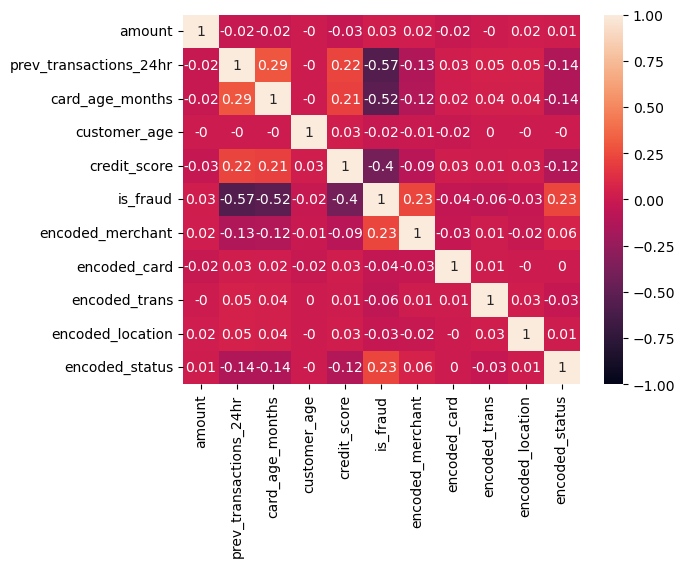

In [11]:
sns.heatmap(correlation,annot = True,vmax = 1, vmin=-1)

In [12]:
x = df[["amount","encoded_merchant","encoded_status"]]
y = df["is_fraud"]

In [13]:
#data splitting:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state =42)

In [14]:
#scaling:
scaler = StandardScaler()
x_train_scalar = scaler.fit_transform(x_train)
x_test_scalar = scaler.transform(x_test)

In [15]:
para_random = {"max_depth" : [3,5,6,7,9,11],
              "n_estimators": [100,150,200,250,300]}

In [16]:
tunning_model = RandomForestClassifier(random_state = 42)

In [17]:
model = RandomizedSearchCV(param_distributions = para_random,
                           estimator = tunning_model,
                           n_jobs= -1,
                           cv = 5,
                          n_iter = 30,
                          scoring = "accuracy")
model.fit(x_train_scalar,y_train)

,estimator,RandomForestC...ndom_state=42)
,param_distributions,"{'max_depth': [3, 5, ...], 'n_estimators': [100, 150, ...]}"
,n_iter,30
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [18]:
model.best_params_

{'n_estimators': 250, 'max_depth': 11}

In [19]:
y_pred = model.predict(x_test_scalar)
accuracy_score(y_test,y_pred)

0.9173354735152488

In [20]:
y_pred_train = model.predict(x_train_scalar)
accuracy_score(y_train,y_pred_train)

0.94723113964687

In [21]:
#confusion_matrix:
confusion_matrix(y_test,y_pred)

array([[956,  48],
       [ 55, 187]])

In [22]:
#precision_score:
precision_score(y_test,y_pred)

0.7957446808510639

In [23]:
#recall score:
recall_score(y_test,y_pred)

0.7727272727272727

In [24]:
#f1 score:
f1_score(y_test,y_pred)

0.7840670859538784

In [26]:
#classification_report:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.95      0.95      0.95      1004
           1       0.80      0.77      0.78       242

    accuracy                           0.92      1246
   macro avg       0.87      0.86      0.87      1246
weighted avg       0.92      0.92      0.92      1246



In [27]:
df.head()

,amount,prev_transactions_24hr,card_age_months,customer_age,credit_score,is_fraud,encoded_merchant,encoded_card,encoded_trans,encoded_location,encoded_status
0,14.44,5,80,26,637,0,1,1,1,0,0
1,185.75,7,61,49,668,0,6,1,4,1,0
2,245.32,4,86,38,628,0,6,0,4,8,2
3,304.05,3,62,30,676,0,6,1,3,8,0
4,255.64,1,24,31,566,0,7,1,3,5,0


In [32]:
#predictive model:
amount = int(input("enter your amount"))
merchant = int(input("enter where you use the card-->{'Dining': 1, 'Grocery': 6, 'Healthcare': 7, 'Online': 9, 'Clothing': 0, 'Fuel': 4, 'Gaming': 5, 'Travel': 10, 'Electronics': 2, 'Utilities': 11, 'Jewelry': 8, 'Entertainment': 3}"))
status = int(input("enter your status of account -->{'Active': 0, 'New': 2, 'Premium': 3, 'Flagged': 1, 'Suspended': 4}"))

data = scaler.transform([[amount,merchant,status]])
predict = model.predict(data)
print("will the customer do credict fraud:", predict)

enter your amount 400
enter where you use the card-->{'Dining': 1, 'Grocery': 6, 'Healthcare': 7, 'Online': 9, 'Clothing': 0, 'Fuel': 4, 'Gaming': 5, 'Travel': 10, 'Electronics': 2, 'Utilities': 11, 'Jewelry': 8, 'Entertainment': 3} 1
enter your status of account -->{'Active': 0, 'New': 2, 'Premium': 3, 'Flagged': 1, 'Suspended': 4} 1


will the customer do credict fraud: [1]


E:\anaconda\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
